# Understanding Partial DINOv2 Fine Tuning

This notebook compares six controlled fine tuning runs on the RTX 3060. It asks whether conservative image augmentation improves a model that trains only the final DINOv2 block, final layer normalization, and seven class head.

The notebook reads completed experiment artifacts. It does not train a model and it does not access Session 3.


## Publication and image rights

This is an independent educational fan project and is not affiliated with Nagano, Chiikawa, or their official rights holders. The photographs show items from my own collection and are included to explain the experiment.

© 2026 Emma Tong. All rights reserved.


## 1. The experiment

The controlled matrix has two configurations and three random seeds.

1. No augmentation uses the prepared Session 1 images as they are.
2. Conservative augmentation applies small crops, rotations, and color changes.
3. Seeds `42`, `123`, and `2026` are used for both configurations.
4. Session 1 supplies 98 training images.
5. Session 2 supplies 42 validation images.
6. Session 3 remains sealed.

Accuracy was already perfect for the frozen retrieval baseline and linear probe. The main evidence is therefore validation cross entropy, confidence margins, behavior across seeds, and performance on the difficult views.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

from usagi_visual_identifier.data.loaders import load_catalog_csv
from usagi_visual_identifier.embeddings import load_embedding_artifact

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 95


def find_project_root(start: Path) -> Path:
    """Find the nearest parent containing the project configuration."""
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from inside the project repository.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
ARTIFACT_ROOT = PROJECT_ROOT / "artifacts"
MODEL_ROOT = ARTIFACT_ROOT / "models/partial_finetune"
PROCESSED_ROOT = PROJECT_ROOT / "data/processed"
PRIVATE_ROOT = PROJECT_ROOT / "data/private"
EMBEDDING_ROOT = ARTIFACT_ROOT / "embeddings/facebook_dinov2-small"

catalog = load_catalog_csv(path=PRIVATE_ROOT / "catalog.csv")
catalog_names = {item.catalog_id: item.display_name for item in catalog.items}
embedding_artifact = load_embedding_artifact(
    artifact_path=EMBEDDING_ROOT / "embeddings.npz",
    metadata_path=EMBEDDING_ROOT / "metadata.json",
)
image_index = {
    image_id: index for index, image_id in enumerate(embedding_artifact.image_ids)
}


def prepared_image_path(image_id: str) -> Path:
    """Resolve one prepared image from its stable ID."""
    index = image_index[image_id]
    return PROCESSED_ROOT / embedding_artifact.processed_relative_paths[index]


def draw_image(axis, image_id: str, title: str) -> None:
    """Display one collection photograph without retaining an open handle."""
    with Image.open(prepared_image_path(image_id)) as opened:
        axis.imshow(opened.convert("RGB"))
    axis.set_title(title)
    axis.axis("off")


run_rows = []
history_frames = []
query_rows = []
reports = {}
for metadata_path in sorted(MODEL_ROOT.glob("*/metadata.json")):
    run_root = metadata_path.parent
    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    history = pd.DataFrame(
        json.loads((run_root / "training_history.json").read_text(encoding="utf-8"))[
            "epochs"
        ]
    )
    report = json.loads(
        (run_root / "validation_report.json").read_text(encoding="utf-8")
    )
    enabled = metadata["configuration"]["augmentation"]["enabled"]
    configuration = "Conservative augmentation" if enabled else "No augmentation"
    run_id = metadata["run_id"]
    seed = metadata["configuration"]["seed"]
    run_rows.append(
        {
            "run_id": run_id,
            "configuration": configuration,
            "seed": seed,
            "selected_epoch": metadata["selected_epoch"],
            "validation_loss": metadata["validation_loss"],
            "top1_accuracy": metadata["validation_metrics"]["top1_accuracy"],
            "training_seconds": metadata["training_seconds"],
            "amp_skips": metadata["amp_skipped_optimizer_steps"],
            "trainable_parameters": metadata["trainable_parameter_count"],
            "total_parameters": metadata["total_parameter_count"],
            "dataset_fingerprint": metadata["dataset_fingerprint"],
            "test_accessed": metadata["test_split_accessed"],
        }
    )
    history = history.assign(run_id=run_id, configuration=configuration, seed=seed)
    history_frames.append(history)
    reports[run_id] = report
    for query in report["queries"]:
        query_rows.append(
            {
                "run_id": run_id,
                "configuration": configuration,
                "seed": seed,
                "image_id": query["image_id"],
                "true_identity": query["true_identity"],
                "predicted_identity": query["predicted_identity"],
                "correct": query["correct"],
                "top_probability": query["top_probability"],
                "probability_margin": query["probability_margin"],
                "cross_entropy": query["cross_entropy"],
                "runner_up_identity": query["ranked_identities"][1]["identity_id"],
            }
        )

runs = pd.DataFrame(run_rows).sort_values(["configuration", "seed"])
histories = pd.concat(history_frames, ignore_index=True)
queries = pd.DataFrame(query_rows)

linear_root = ARTIFACT_ROOT / "models/linear_probe/582a6d5094cc"
linear_metadata = json.loads(
    (linear_root / "metadata.json").read_text(encoding="utf-8")
)
linear_report = json.loads(
    (linear_root / "validation_report.json").read_text(encoding="utf-8")
)
retrieval_report = json.loads(
    (
        ARTIFACT_ROOT
        / "evaluations/dinov2_small/aggregation_comparison_train_to_validation.json"
    ).read_text(encoding="utf-8")
)

assert len(runs) == 6
assert runs["dataset_fingerprint"].nunique() == 1
assert not runs["test_accessed"].any()
assert set(runs["seed"]) == {42, 123, 2026}
assert set(runs.groupby("configuration").size()) == {3}

print("Verified six partial fine tuning runs")
print(f"Dataset fingerprint: {runs['dataset_fingerprint'].iloc[0]}")
print(f"Session 3 accessed: {runs['test_accessed'].any()}")

Verified six partial fine tuning runs
Dataset fingerprint: 27c73c3bc69640bb10b36f4846270847dea4fe871cedeee516b7f58badd9a634
Session 3 accessed: False


## 2. What conservative augmentation looks like

Augmentation creates a new random training view in memory. It does not edit or duplicate the original JPEG. The gallery below applies the exact reviewed configuration to one photograph.

The changes include a crop that keeps at least 88 percent of the original scale, a rotation of at most 6 degrees, brightness and contrast changes of at most 12 percent, saturation changes of at most 8 percent, and a very small hue shift. Horizontal reflection and random erasing are excluded because they could reverse a tag or hide an identity cue.

Each variant keeps the Lobster claws, face, body shape, and tag recognizable. That is what makes this policy conservative. The view changes, but the correct identity should not.


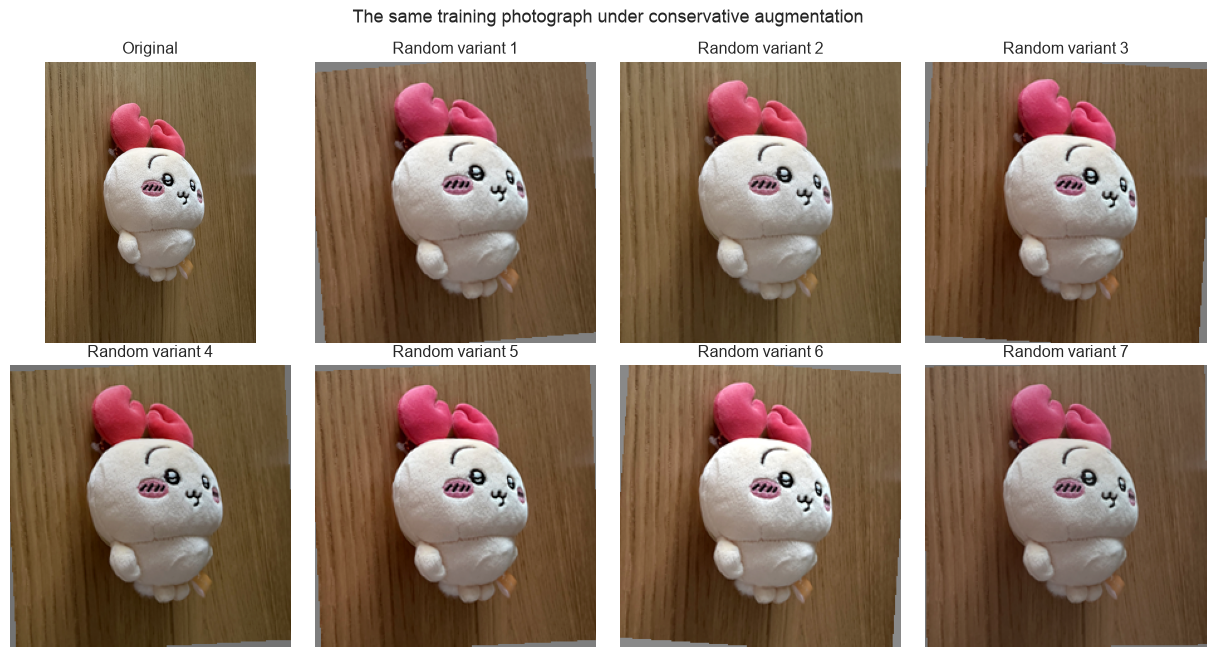

In [2]:
import torch

from usagi_visual_identifier.training import (
    build_training_augmentation,
    load_partial_finetune_config,
)

augmentation_config = load_partial_finetune_config(
    path=PROJECT_ROOT / "configs/partial_finetune/conservative.json"
).augmentation
augmentation = build_training_augmentation(augmentation_config)
assert augmentation is not None

example_image_id = "img-000138"
with Image.open(prepared_image_path(example_image_id)) as opened:
    original = opened.convert("RGB")

fig, axes = plt.subplots(2, 4, figsize=(13, 7))
draw_image(axes.flat[0], example_image_id, "Original")
for variant_number, axis in enumerate(axes.flat[1:], start=1):
    torch.manual_seed(100 + variant_number)
    variant = augmentation(original)
    assert isinstance(variant, Image.Image)
    axis.imshow(variant)
    axis.set_title(f"Random variant {variant_number}")
    axis.axis("off")
    variant.close()
original.close()
fig.suptitle(
    "The same training photograph under conservative augmentation", fontsize=14
)
plt.tight_layout()
plt.show()

## 2. What was trained

DINOv2 Small has twelve transformer blocks and produces a 384 value CLS representation. This experiment updates only the final transformer block, final layer normalization, and affine head. Every earlier DINOv2 weight stays frozen.

The head produces seven logits, one for each known doll identity. Softmax converts the logits into probabilities for reporting. L2 normalization and softmax contain no learned weights.


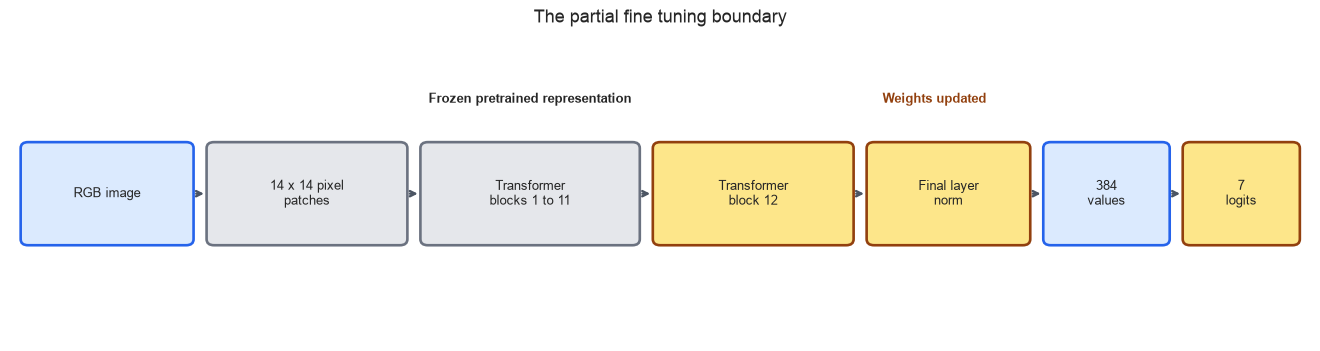

Trainable parameters: 1,778,695 of 22,059,271 (8.1%)


In [3]:
import itertools

from matplotlib.patches import FancyBboxPatch

fig, axis = plt.subplots(figsize=(14, 3.8))
axis.set_xlim(0, 14)
axis.set_ylim(0, 4)
axis.axis("off")

nodes = [
    (0.2, 1.35, 1.7, "RGB image", "#dbeafe", "#2563eb"),
    (2.2, 1.35, 2.0, "14 x 14 pixel\npatches", "#e5e7eb", "#6b7280"),
    (4.5, 1.35, 2.2, "Transformer\nblocks 1 to 11", "#e5e7eb", "#6b7280"),
    (7.0, 1.35, 2.0, "Transformer\nblock 12", "#fde68a", "#92400e"),
    (9.3, 1.35, 1.6, "Final layer\nnorm", "#fde68a", "#92400e"),
    (11.2, 1.35, 1.2, "384\nvalues", "#dbeafe", "#2563eb"),
    (12.7, 1.35, 1.1, "7\nlogits", "#fde68a", "#92400e"),
]
for x, y, width, label, fill, edge in nodes:
    axis.add_patch(
        FancyBboxPatch(
            (x, y),
            width,
            1.2,
            boxstyle="round,pad=0.08",
            facecolor=fill,
            edgecolor=edge,
            linewidth=2,
        )
    )
    axis.text(x + width / 2, y + 0.6, label, ha="center", va="center")
for left, right in itertools.pairwise(nodes):
    axis.annotate(
        "",
        xy=(right[0] - 0.08, 1.95),
        xytext=(left[0] + left[2] + 0.08, 1.95),
        arrowprops={"arrowstyle": "->", "color": "#4b5563", "lw": 1.8},
    )
axis.text(5.6, 3.15, "Frozen pretrained representation", ha="center", weight="bold")
axis.text(9.95, 3.15, "Weights updated", ha="center", weight="bold", color="#92400e")
axis.set_title("The partial fine tuning boundary", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

trainable = int(runs["trainable_parameters"].iloc[0])
total = int(runs["total_parameters"].iloc[0])
print(f"Trainable parameters: {trainable:,} of {total:,} ({trainable / total:.1%})")

## 3. Run inventory

Every row below is an independent training run. The selected epoch is the checkpoint with the lowest validation loss, not necessarily the final epoch executed. Early stopping ends training after eight epochs without sufficient improvement.


In [4]:
inventory = runs[
    [
        "configuration",
        "seed",
        "run_id",
        "selected_epoch",
        "validation_loss",
        "top1_accuracy",
        "training_seconds",
        "amp_skips",
    ]
].copy()
inventory["training_minutes"] = inventory.pop("training_seconds") / 60
display(
    inventory.style.format(
        {
            "validation_loss": "{:.6f}",
            "top1_accuracy": "{:.3f}",
            "training_minutes": "{:.1f}",
        }
    )
)

,configuration,seed,run_id,selected_epoch,validation_loss,top1_accuracy,amp_skips,training_minutes
4,Conservative augmentation,42,c62a6ff28d2e,22,0.002307,1.000,1,13.1
2,Conservative augmentation,123,765a555cffa6,9,0.004439,1.000,0,7.5
0,Conservative augmentation,2026,22ff26ebd272,19,0.003471,1.000,1,11.7
3,No augmentation,42,b410e9d55549,26,0.006019,1.000,0,13.7
5,No augmentation,123,f1da889ad75f,3,0.006266,1.000,0,4.4
1,No augmentation,2026,4b82df481d14,15,0.005924,1.000,0,9.4


## 4. Learning curves and checkpoint selection

Training loss becomes extremely small for every run. Validation loss is more useful because it measures behavior on the independent Session 2 capture. The vertical dotted line marks the selected checkpoint for each seed.

The curves also show why the final epoch is not automatically the best model. Once validation loss stops improving, additional optimization mostly increases confidence on the training photographs.


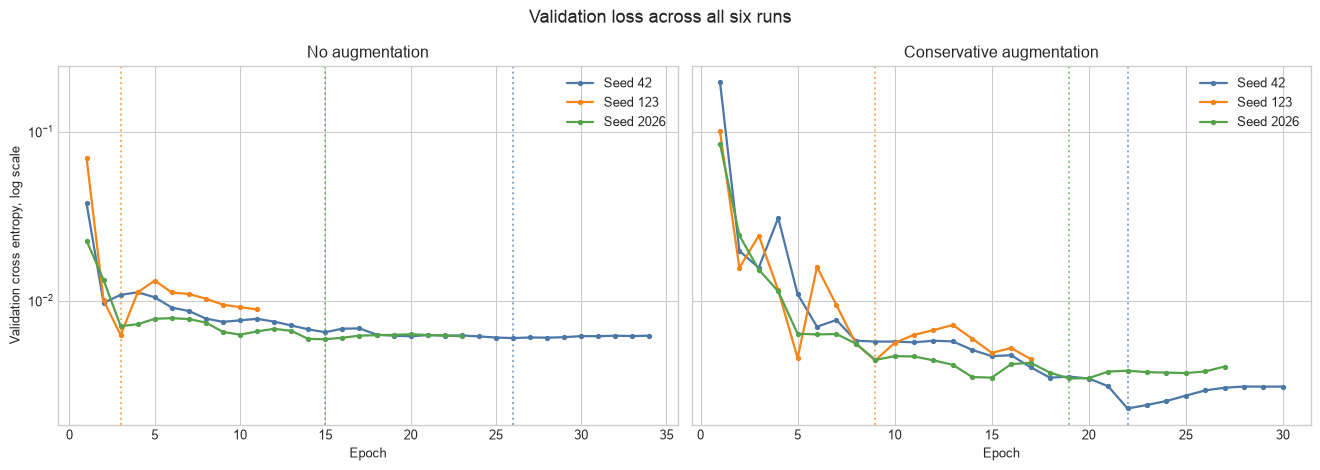

In [5]:
colors = {42: "#4c78a8", 123: "#f58518", 2026: "#54a24b"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for axis, configuration in zip(
    axes,
    ["No augmentation", "Conservative augmentation"],
    strict=True,
):
    subset = histories[histories["configuration"] == configuration]
    for seed in (42, 123, 2026):
        curve = subset[subset["seed"] == seed]
        selected_epoch = int(
            runs.loc[
                (runs["configuration"] == configuration) & (runs["seed"] == seed),
                "selected_epoch",
            ].iloc[0]
        )
        axis.plot(
            curve["epoch"],
            curve["validation_loss"],
            marker="o",
            markersize=3,
            linewidth=1.7,
            color=colors[seed],
            label=f"Seed {seed}",
        )
        axis.axvline(selected_epoch, color=colors[seed], linestyle=":", alpha=0.65)
    axis.set_title(configuration)
    axis.set_xlabel("Epoch")
    axis.set_yscale("log")
    axis.legend()
axes[0].set_ylabel("Validation cross entropy, log scale")
fig.suptitle("Validation loss across all six runs", fontsize=14)
plt.tight_layout()
plt.show()

## 5. A paired comparison across seeds

Each seed appears once under each augmentation policy. Connecting matching seeds removes some noise caused by initialization and batch order. Lower validation loss is better.


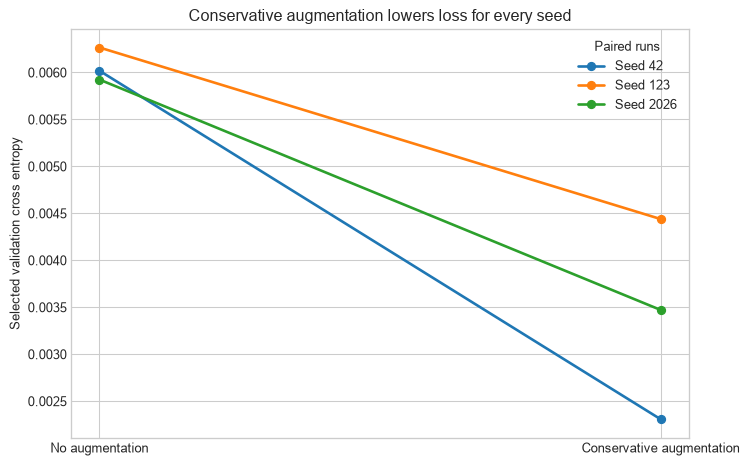

,mean_validation_loss,standard_deviation,mean_selected_epoch,mean_training_minutes
configuration,,,,
Conservative augmentation,0.003406,0.001067,16.666667,10.758074
No augmentation,0.006070,0.000176,14.666667,9.149883


Mean loss reduction: 43.9%


In [6]:
pivot_loss = runs.pivot(index="seed", columns="configuration", values="validation_loss")
fig, axis = plt.subplots(figsize=(8, 5))
x_positions = [0, 1]
for seed, row in pivot_loss.iterrows():
    values = [row["No augmentation"], row["Conservative augmentation"]]
    axis.plot(x_positions, values, marker="o", linewidth=2, label=f"Seed {seed}")
axis.set_xticks(x_positions, ["No augmentation", "Conservative augmentation"])
axis.set_ylabel("Selected validation cross entropy")
axis.set_title("Conservative augmentation lowers loss for every seed")
axis.legend(title="Paired runs")
plt.tight_layout()
plt.show()

summary = runs.groupby("configuration").agg(
    mean_validation_loss=("validation_loss", "mean"),
    standard_deviation=("validation_loss", "std"),
    mean_selected_epoch=("selected_epoch", "mean"),
    mean_training_minutes=("training_seconds", lambda values: values.mean() / 60),
)
display(summary.style.format("{:.6f}"))

no_aug_loss = summary.loc["No augmentation", "mean_validation_loss"]
aug_loss = summary.loc["Conservative augmentation", "mean_validation_loss"]
relative_reduction = (no_aug_loss - aug_loss) / no_aug_loss
print(f"Mean loss reduction: {relative_reduction:.1%}")

The conservative policy wins for all three paired seeds. Its mean selected validation loss is about 44 percent lower. With only three seeds and 42 validation photographs, this is useful project evidence rather than a formal claim about all possible Usagi photographs.


## 6. Accuracy has reached its ceiling

Frozen nearest image retrieval, the linear probe, and all six partial fine tuning runs classify every Session 2 photograph correctly. Accuracy therefore cannot tell us which representation is strongest.

Cross entropy can still distinguish the supervised models because it responds to how much probability they assign to the correct identity. Retrieval does not produce the same seven class probability distribution, so it is included in the accuracy comparison but not the loss comparison.


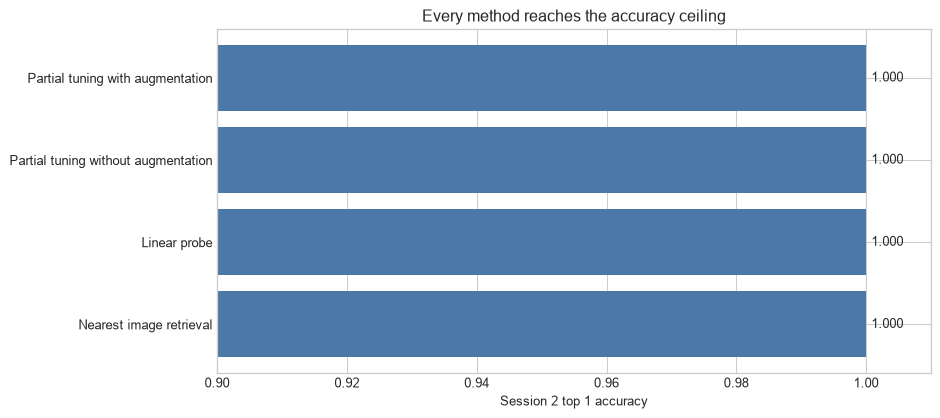

In [7]:
retrieval_top1 = next(
    report["top1_accuracy"]
    for report in retrieval_report["reports"]
    if report["aggregation"]["method"] == "nearest_image"
)
accuracy_rows = pd.DataFrame(
    {
        "method": [
            "Nearest image retrieval",
            "Linear probe",
            "Partial tuning without augmentation",
            "Partial tuning with augmentation",
        ],
        "validation_top1": [
            retrieval_top1,
            linear_metadata["validation_metrics"]["top1_accuracy"],
            runs.loc[
                runs["configuration"] == "No augmentation", "top1_accuracy"
            ].mean(),
            runs.loc[
                runs["configuration"] == "Conservative augmentation", "top1_accuracy"
            ].mean(),
        ],
    }
)
fig, axis = plt.subplots(figsize=(10, 4.5))
bars = axis.barh(
    accuracy_rows["method"], accuracy_rows["validation_top1"], color="#4c78a8"
)
axis.set_xlim(0.9, 1.01)
axis.set_xlabel("Session 2 top 1 accuracy")
axis.set_title("Every method reaches the accuracy ceiling")
axis.bar_label(bars, fmt="%.3f", padding=4)
plt.tight_layout()
plt.show()

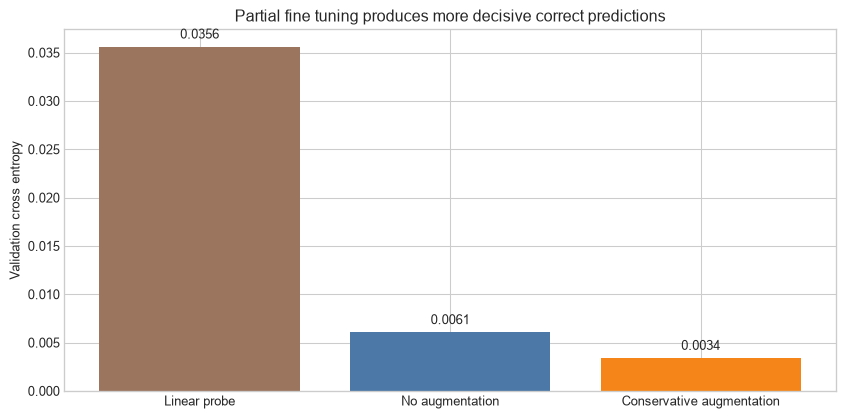

In [8]:
loss_comparison = pd.DataFrame(
    {
        "model": ["Linear probe", "No augmentation", "Conservative augmentation"],
        "mean_loss": [
            linear_metadata["validation_loss"],
            no_aug_loss,
            aug_loss,
        ],
    }
)
fig, axis = plt.subplots(figsize=(9, 4.5))
bars = axis.bar(
    loss_comparison["model"],
    loss_comparison["mean_loss"],
    color=["#9c755f", "#4c78a8", "#f58518"],
)
axis.set_ylabel("Validation cross entropy")
axis.set_title("Partial fine tuning produces more decisive correct predictions")
axis.bar_label(bars, fmt="%.4f", padding=4)
plt.tight_layout()
plt.show()

## 7. Confidence margins

The probability margin is the predicted identity probability minus the runner up probability. A larger positive margin means the model separates its first and second choices more strongly.

High confidence is not automatically proof of generalization. Here it is useful mainly for locating fragile views and comparing the same validation photographs under controlled runs.


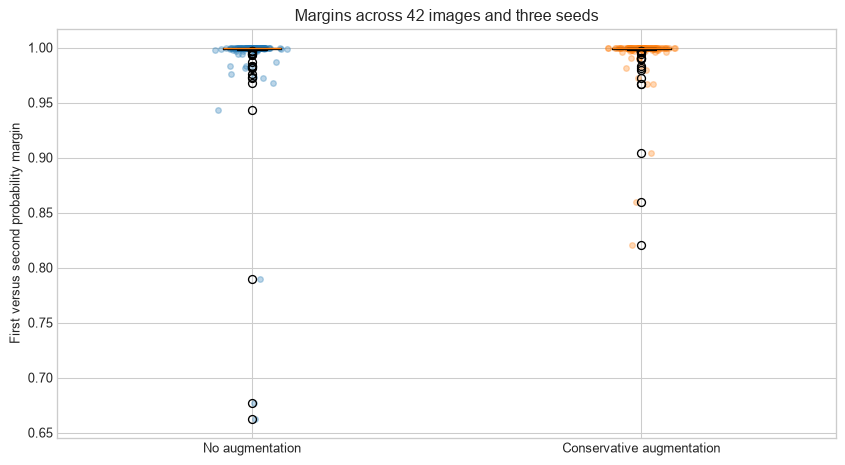

In [9]:
fig, axis = plt.subplots(figsize=(9, 5))
groups = [
    queries.loc[queries["configuration"] == configuration, "probability_margin"]
    for configuration in ["No augmentation", "Conservative augmentation"]
]
axis.boxplot(
    groups,
    tick_labels=["No augmentation", "Conservative augmentation"],
    showfliers=True,
)
for position, values in enumerate(groups, start=1):
    jitter = np.random.default_rng(position).normal(position, 0.035, len(values))
    axis.scatter(jitter, values, alpha=0.3, s=18)
axis.set_ylabel("First versus second probability margin")
axis.set_title("Margins across 42 images and three seeds")
plt.tight_layout()
plt.show()

## 8. The least decisive photographs

For each validation image, the next table averages its margin across all six runs. The six smallest averages identify the views that remain most informative even though every prediction is correct.


,image_id,doll,mean_margin,minimum_margin,mean_cross_entropy
39,img-000138,Lobster claws,0.7855,0.6621,0.1410
38,img-000137,Lobster claws,0.9721,0.9433,0.0180
37,img-000136,Lobster claws,0.9765,0.9665,0.0144
36,img-000135,Lobster claws,0.9820,0.9681,0.0095
41,img-000140,Lobster claws,0.9959,0.9942,0.0024
8,img-000107,Airport,0.9967,0.9949,0.0020


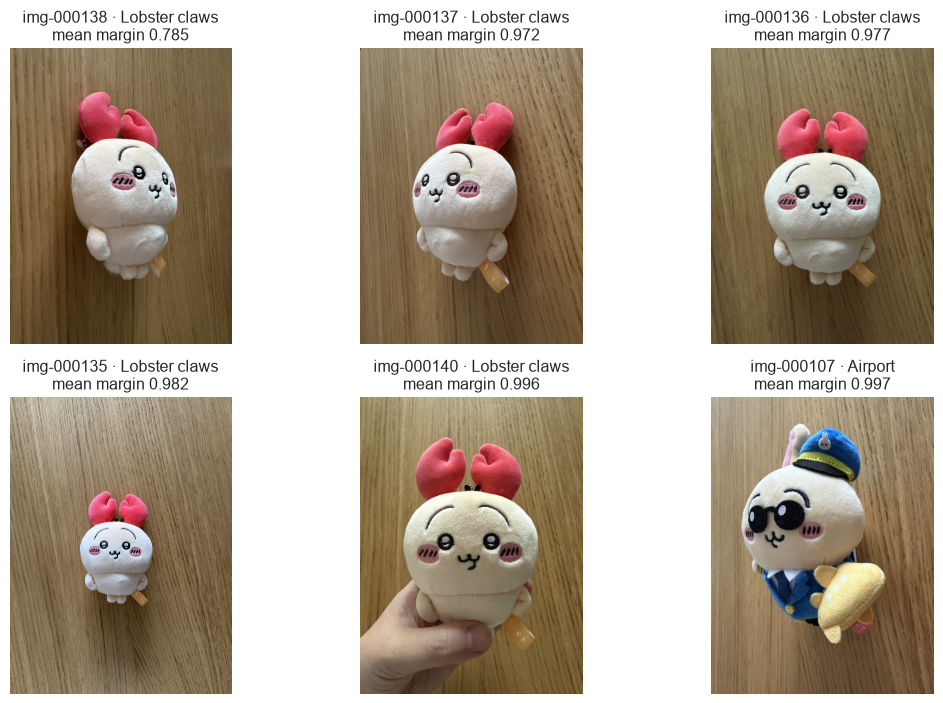

In [10]:
hardest = (
    queries.groupby(["image_id", "true_identity"], as_index=False)
    .agg(
        mean_margin=("probability_margin", "mean"),
        minimum_margin=("probability_margin", "min"),
        mean_cross_entropy=("cross_entropy", "mean"),
    )
    .nsmallest(6, "mean_margin")
)
hardest["doll"] = hardest["true_identity"].map(catalog_names)
display(
    hardest[
        ["image_id", "doll", "mean_margin", "minimum_margin", "mean_cross_entropy"]
    ].style.format(
        {
            "mean_margin": "{:.4f}",
            "minimum_margin": "{:.4f}",
            "mean_cross_entropy": "{:.4f}",
        }
    )
)

fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for axis, row in zip(axes.flat, hardest.itertuples(), strict=True):
    draw_image(
        axis,
        row.image_id,
        f"{row.image_id} · {row.doll}\nmean margin {row.mean_margin:.3f}",
    )
plt.tight_layout()
plt.show()

The Lobster claws doll supplies four of the five hardest views. `img-000138` remains the clearest stress case. This agrees with the earlier linear probe analysis and makes it a useful image to follow across experiments.


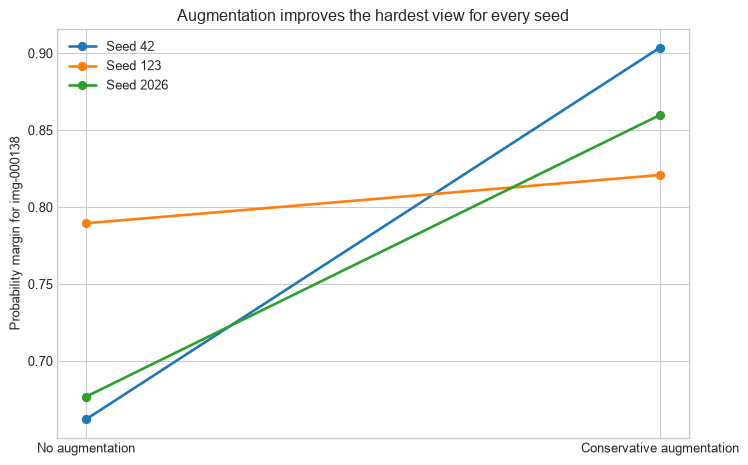

configuration
Conservative augmentation    0.861523
No augmentation              0.709458
Margin improvement: 0.152


In [11]:
lobster_image = "img-000138"
lobster = queries[queries["image_id"] == lobster_image].copy()
lobster_pivot = lobster.pivot(
    index="seed", columns="configuration", values="probability_margin"
)
fig, axis = plt.subplots(figsize=(8, 5))
for seed, row in lobster_pivot.iterrows():
    axis.plot(
        [0, 1],
        [row["No augmentation"], row["Conservative augmentation"]],
        marker="o",
        linewidth=2,
        label=f"Seed {seed}",
    )
axis.set_xticks([0, 1], ["No augmentation", "Conservative augmentation"])
axis.set_ylabel("Probability margin for img-000138")
axis.set_title("Augmentation improves the hardest view for every seed")
axis.legend()
plt.tight_layout()
plt.show()

lobster_means = lobster.groupby("configuration")["probability_margin"].mean()
print(lobster_means.to_string())
print(
    "Margin improvement: "
    f"{lobster_means['Conservative augmentation'] - lobster_means['No augmentation']:.3f}"
)

## 9. Per identity behavior

A perfect aggregate accuracy can hide a class that requires much more probability mass to classify correctly. Mean cross entropy by identity shows which doll contributes most to the remaining validation loss.


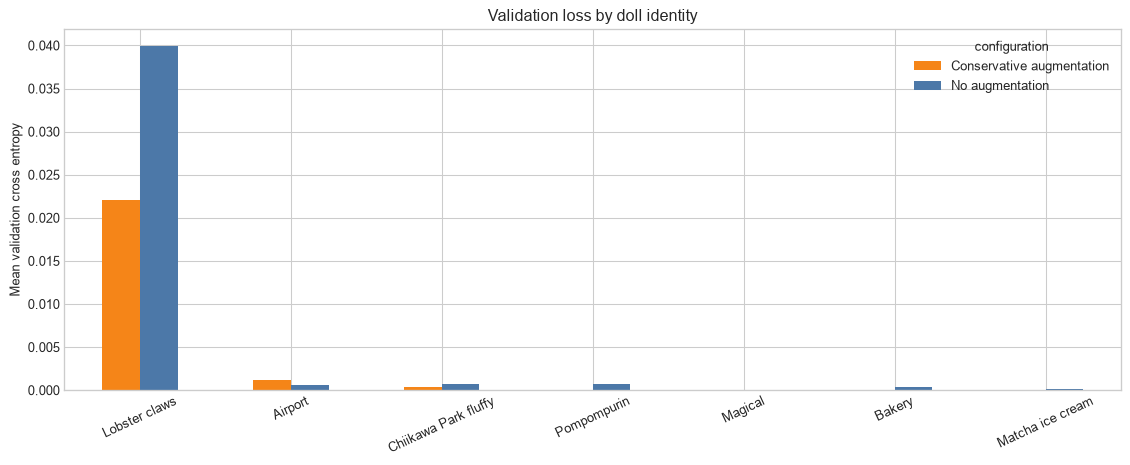

configuration,Conservative augmentation,No augmentation
doll,,
Lobster claws,0.02210,0.03992
Airport,0.00115,0.00059
Chiikawa Park fluffy,0.00041,0.00069
Pompompurin,0.00006,0.00073
Magical,0.00006,0.00008
Bakery,0.00004,0.00036
Matcha ice cream,0.00002,0.00012


In [12]:
identity_loss = queries.groupby(["configuration", "true_identity"], as_index=False)[
    "cross_entropy"
].mean()
identity_loss["doll"] = identity_loss["true_identity"].map(catalog_names)
pivot_identity = identity_loss.pivot(
    index="doll", columns="configuration", values="cross_entropy"
).sort_values("Conservative augmentation", ascending=False)

axis = pivot_identity.plot.bar(figsize=(12, 5), color=["#f58518", "#4c78a8"])
axis.set_ylabel("Mean validation cross entropy")
axis.set_xlabel("")
axis.set_title("Validation loss by doll identity")
axis.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

display(pivot_identity.style.format("{:.5f}"))

## 10. Training cost and AMP recovery

Augmentation performs image transformations during every training batch, so some extra time is expected. AMP skipped steps count batches whose FP16 gradients overflowed while the dynamic scale settled. PyTorch skipped those unsafe updates and continued after reducing the scale.


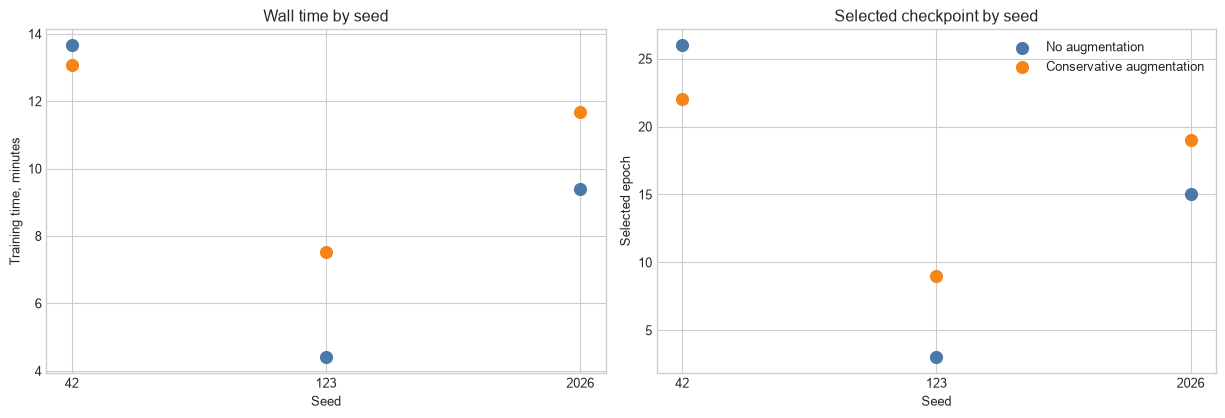

Total RTX 3060 training time: 59.7 minutes
Total AMP skipped optimizer steps: 2


In [13]:
cost = runs.copy()
cost["training_minutes"] = cost["training_seconds"] / 60
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for configuration, color in [
    ("No augmentation", "#4c78a8"),
    ("Conservative augmentation", "#f58518"),
]:
    subset = cost[cost["configuration"] == configuration]
    axes[0].scatter(
        subset["seed"].astype(str),
        subset["training_minutes"],
        s=80,
        label=configuration,
        color=color,
    )
    axes[1].scatter(
        subset["seed"].astype(str),
        subset["selected_epoch"],
        s=80,
        label=configuration,
        color=color,
    )
axes[0].set_title("Wall time by seed")
axes[0].set_xlabel("Seed")
axes[0].set_ylabel("Training time, minutes")
axes[1].set_title("Selected checkpoint by seed")
axes[1].set_xlabel("Seed")
axes[1].set_ylabel("Selected epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Total RTX 3060 training time: {cost['training_minutes'].sum():.1f} minutes")
print(f"Total AMP skipped optimizer steps: {int(cost['amp_skips'].sum())}")

## 11. What these results support

The evidence supports conservative augmentation for this partial fine tuning setup:

1. It lowers selected validation loss for every matched seed.
2. It reduces mean validation loss by about 44 percent.
3. It improves the margin of the hardest photograph, `img-000138`, for every seed.
4. All runs retain perfect Session 2 accuracy and macro recall.
5. The two AMP overflows are confined to the first epoch and recover normally.

The evidence does not yet show that partial fine tuning is the best production model. Session 2 contains only 42 photographs from one capture session, and higher softmax confidence can reflect sharper fitting rather than broader real world robustness.


## 12. Decision and next evaluation

Conservative augmentation is the selected partial fine tuning configuration. The three seed runs remain separate evidence rather than being combined into one model. Before Session 3 is opened, I will choose one deterministic checkpoint selection rule and freeze every remaining decision.

The final comparison must include:

1. Frozen nearest image retrieval
2. The selected linear probe
3. The selected partial fine tuning checkpoint
4. Accuracy and per identity results on Session 3
5. Confidence margins and the specific errors, if any
6. A separate unknown item rejection experiment later

Until that protocol is frozen, Session 3 remains untouched.
